In [46]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.model_selection import train_test_split
import joblib

In [16]:
#!pip install numpy pandas faker
import pandas as p
import numpy as np
import random
from faker import Faker

fake = Faker()
num_samples = 100000  # Number of non-fraudulent users

# Generate synthetic non-fraudulent user data
data = {
    "user_id": [fake.uuid4() for _ in range(num_samples)],
    "age": np.random.randint(18, 70, num_samples),
    "gender": np.random.choice(["Male", "Female", "Other"], num_samples),
    "latitude": np.random.uniform(-90, 90, num_samples),
    "longitude": np.random.uniform(-180, 180, num_samples),
    "country": [fake.country() for _ in range(num_samples)],
    "city": [fake.city() for _ in range(num_samples)],
    "account_creation_date": [fake.date_this_decade() for _ in range(num_samples)],
    "account_type": np.random.choice(["Personal", "Business", "Admin"], num_samples, p=[0.8, 0.15, 0.05]),
    "subscription_plan": np.random.choice(["Free", "Basic", "Premium"], num_samples, p=[0.6, 0.3, 0.1]),
    "email_domain": np.random.choice(["gmail.com", "yahoo.com", "outlook.com", "protonmail.com"], num_samples),
    "phone_number_prefix": np.random.choice(["+1", "+44", "+91", "+81", "+33"], num_samples),

    # Behavioral Features
    "session_duration_avg": np.random.uniform(5, 120, num_samples),
    "time_spent_per_action": np.random.uniform(0.5, 15, num_samples),
    "number_of_sessions_per_day": np.random.randint(1, 10, num_samples),
    "device_type": np.random.choice(["PC", "Mobile", "Tablet"], num_samples, p=[0.5, 0.4, 0.1]),
    "browser_type": np.random.choice(["Chrome", "Firefox", "Safari", "Edge", "Opera"], num_samples),
    "OS": np.random.choice(["Windows", "Linux", "macOS", "Android", "iOS"], num_samples),
    "most_active_hours": np.random.randint(0, 24, num_samples),
    "weekend_vs_weekday_activity_ratio": np.random.uniform(0.5, 1.5, num_samples),
    "login_frequency_per_week": np.random.randint(1, 20, num_samples),
    "failed_login_attempts": np.random.randint(0, 5, num_samples),
    "password_reset_requests": np.random.randint(0, 3, num_samples),

    # Transactional Features
    "total_transactions": np.random.randint(5, 500, num_samples),
    "avg_transaction_value": np.random.uniform(10, 1000, num_samples),
    "max_transaction_value": np.random.uniform(100, 10000, num_samples),
    "min_transaction_value": np.random.uniform(1, 50, num_samples),
    "number_of_refunds": np.random.randint(0, 5, num_samples),
    "chargeback_ratio": np.random.uniform(0, 0.05, num_samples),
    "number_of_failed_transactions": np.random.randint(0, 3, num_samples),
    "payment_methods_used": np.random.choice(["Credit Card", "PayPal", "Crypto", "Bank Transfer"], num_samples),

    # Social & Interaction Features
    "number_of_friends": np.random.randint(0, 500, num_samples),
    "number_of_messages_sent": np.random.randint(0, 1000, num_samples),
    "number_of_posts": np.random.randint(0, 300, num_samples),
    "most_active_community": np.random.choice(["Tech", "Finance", "Gaming", "Health", "Education"], num_samples),
    "engagement_score": np.random.uniform(0, 1, num_samples),

    # Network & Device Anomaly Features
    "IP_address_diversity": np.random.randint(1, 10, num_samples),
    "VPN_or_Proxy_usage": np.random.choice([0, 1], num_samples, p=[0.95, 0.05]),  # 5% use VPNs
    "device_switching_frequency": np.random.randint(0, 5, num_samples),
    "MAC_address_changes": np.random.randint(0, 3, num_samples),
    "number_of_sessions_from_unusual_locations": np.random.randint(0, 2, num_samples),
    "average_network_latency": np.random.uniform(20, 300, num_samples),
    "packet_loss_rate": np.random.uniform(0, 5, num_samples),

    # Security & Risk Features
    "number_of_failed_captcha_attempts": np.random.randint(0, 2, num_samples),
    "multi_factor_authentication_enabled": np.random.choice([0, 1], num_samples, p=[0.7, 0.3]),  # 30% use MFA
    "account_suspension_count": np.zeros(num_samples),  # Non-fraudulent users should have 0 suspensions
    "fraud_report_count": np.zeros(num_samples),
    "password_change_frequency": np.random.randint(0, 5, num_samples),
    "device_trust_score": np.random.uniform(0.7, 1.0, num_samples),

    # Anomaly-Specific Features
    "outlier_score": np.random.uniform(0, 0.2, num_samples),
    "transaction_pattern_anomaly_score": np.random.uniform(0, 0.2, num_samples),
    "time_series_anomaly_score": np.random.uniform(0, 0.2, num_samples),
    "fraud_risk_score": np.random.uniform(0, 0.1, num_samples),  # Should be very low for non-fraudulent users
}

# Convert to DataFrame
df_non_fraud = pd.DataFrame(data)
df_non_fraud.to_csv('non_fraud_night_1.csv', index=False)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 26.4 MB/s eta 0:00:00


In [19]:
# Generate synthetic fraudulent user data
num_fraud_samples = 2000  # Number of fraudulent users

fraud_data = {
    "user_id": [fake.uuid4() for _ in range(num_fraud_samples)],
    "age": np.random.randint(18, 70, num_fraud_samples),
    "gender": np.random.choice(["Male", "Female", "Other"], num_fraud_samples),
    "latitude": np.random.uniform(-90, 90, num_fraud_samples),
    "longitude": np.random.uniform(-180, 180, num_fraud_samples),
    "country": [fake.country() for _ in range(num_fraud_samples)],
    "city": [fake.city() for _ in range(num_fraud_samples)],
    "account_creation_date": [fake.date_this_year() for _ in range(num_fraud_samples)],
    "account_type": np.random.choice(["Personal", "Business", "Admin"], num_fraud_samples, p=[0.6, 0.3, 0.1]),
    "subscription_plan": np.random.choice(["Free", "Basic", "Premium"], num_fraud_samples, p=[0.7, 0.2, 0.1]),
    "email_domain": np.random.choice(["tempmail.com", "disposable.com", "randommail.net", "protonmail.com"], num_fraud_samples),
    "phone_number_prefix": np.random.choice(["+999", "+888", "+777", "+666", "+555"], num_fraud_samples),

    # Behavioral Features (Fraudsters have unusual behaviors)
    "session_duration_avg": np.random.uniform(1, 10, num_fraud_samples),  # Very short sessions
    "time_spent_per_action": np.random.uniform(0.1, 2, num_fraud_samples),
    "number_of_sessions_per_day": np.random.randint(10, 50, num_fraud_samples),  # Unusually high activity
    "device_type": np.random.choice(["PC", "Mobile", "Tablet"], num_fraud_samples, p=[0.3, 0.6, 0.1]),
    "browser_type": np.random.choice(["Chrome", "Firefox", "Unknown", "BotBrowser"], num_fraud_samples),
    "OS": np.random.choice(["Windows", "Linux", "macOS", "Android", "iOS"], num_fraud_samples),
    "most_active_hours": np.random.randint(0, 24, num_fraud_samples),
    "weekend_vs_weekday_activity_ratio": np.random.uniform(2, 5, num_fraud_samples),  # More active on weekends
    "login_frequency_per_week": np.random.randint(20, 100, num_fraud_samples),  # Excessive logins
    "failed_login_attempts": np.random.randint(5, 50, num_fraud_samples),  # Many failed attempts
    "password_reset_requests": np.random.randint(3, 10, num_fraud_samples),

    # Transactional Features (Fraudsters often have high variability)
    "total_transactions": np.random.randint(50, 2000, num_fraud_samples),
    "avg_transaction_value": np.random.uniform(500, 5000, num_fraud_samples),
    "max_transaction_value": np.random.uniform(1000, 50000, num_fraud_samples),
    "min_transaction_value": np.random.uniform(0.1, 100, num_fraud_samples),
    "number_of_refunds": np.random.randint(5, 50, num_fraud_samples),
    "chargeback_ratio": np.random.uniform(0.1, 0.9, num_fraud_samples),  # High chargeback ratio
    "number_of_failed_transactions": np.random.randint(5, 30, num_fraud_samples),
    "payment_methods_used": np.random.choice(["Stolen Card", "Crypto", "Anonymous Payment", "Gift Cards"], num_fraud_samples),

    # Social & Interaction Features (Bot-like or abnormal behavior)
    "number_of_friends": np.random.randint(0, 10, num_fraud_samples),  # Few social connections
    "number_of_messages_sent": np.random.randint(0, 5000, num_fraud_samples),  # Very high message count
    "number_of_posts": np.random.randint(0, 5, num_fraud_samples),  # Low post activity
    "most_active_community": np.random.choice(["Scam", "Dark Web", "Gambling", "Fake News"], num_fraud_samples),
    "engagement_score": np.random.uniform(0, 0.2, num_fraud_samples),

    # Network & Device Anomaly Features (Unusual access patterns)
    "IP_address_diversity": np.random.randint(5, 50, num_fraud_samples),  # Many different IPs used
    "VPN_or_Proxy_usage": np.random.choice([0, 1], num_fraud_samples, p=[0.2, 0.8]),  # 80% use VPNs
    "device_switching_frequency": np.random.randint(5, 20, num_fraud_samples),
    "MAC_address_changes": np.random.randint(3, 10, num_fraud_samples),
    "number_of_sessions_from_unusual_locations": np.random.randint(2, 10, num_fraud_samples),
    "average_network_latency": np.random.uniform(300, 1000, num_fraud_samples),  # High latency due to VPNs
    "packet_loss_rate": np.random.uniform(5, 20, num_fraud_samples),

    # Security & Risk Features (Suspicious activities)
    "number_of_failed_captcha_attempts": np.random.randint(2, 10, num_fraud_samples),
    "multi_factor_authentication_enabled": np.random.choice([0, 1], num_fraud_samples, p=[0.9, 0.1]),  # Most don't use MFA
    "account_suspension_count": np.random.randint(1, 5, num_fraud_samples),
    "fraud_report_count": np.random.randint(1, 10, num_fraud_samples),
    "password_change_frequency": np.random.randint(5, 20, num_fraud_samples),
    "device_trust_score": np.random.uniform(0, 0.5, num_fraud_samples),  # Low trust score

    # Anomaly-Specific Features (Fraud markers)
    "outlier_score": np.random.uniform(0.5, 1.5, num_fraud_samples),
    "transaction_pattern_anomaly_score": np.random.uniform(0.5, 1.5, num_fraud_samples),
    "time_series_anomaly_score": np.random.uniform(0.5, 1.5, num_fraud_samples),
    "fraud_risk_score": np.random.uniform(0.7, 1.0, num_fraud_samples),  # Very high fraud risk
}

# Convert to DataFrame
df_fraud = pd.DataFrame(fraud_data)
df_fraud.head()
# Generate synthetic fraudulent user data
num_fraud_samples = 2500  # Number of fraudulent users

fraud_data = {
    "user_id": [fake.uuid4() for _ in range(num_fraud_samples)],
    "age": np.random.randint(18, 70, num_fraud_samples),
    "gender": np.random.choice(["Male", "Female", "Other"], num_fraud_samples),
    "latitude": np.random.uniform(-90, 90, num_fraud_samples),
    "longitude": np.random.uniform(-180, 180, num_fraud_samples),
    "country": [fake.country() for _ in range(num_fraud_samples)],
    "city": [fake.city() for _ in range(num_fraud_samples)],
    "account_creation_date": [fake.date_this_year() for _ in range(num_fraud_samples)],
    "account_type": np.random.choice(["Personal", "Business", "Admin"], num_fraud_samples, p=[0.6, 0.3, 0.1]),
    "subscription_plan": np.random.choice(["Free", "Basic", "Premium"], num_fraud_samples, p=[0.7, 0.2, 0.1]),
    "email_domain": np.random.choice(["tempmail.com", "disposable.com", "randommail.net", "protonmail.com"], num_fraud_samples),
    "phone_number_prefix": np.random.choice(["+999", "+888", "+777", "+666", "+555"], num_fraud_samples),

    # Behavioral Features (Fraudsters have unusual behaviors)
    "session_duration_avg": np.random.uniform(1, 10, num_fraud_samples),  # Very short sessions
    "time_spent_per_action": np.random.uniform(0.1, 2, num_fraud_samples),
    "number_of_sessions_per_day": np.random.randint(10, 50, num_fraud_samples),  # Unusually high activity
    "device_type": np.random.choice(["PC", "Mobile", "Tablet"], num_fraud_samples, p=[0.3, 0.6, 0.1]),
    "browser_type": np.random.choice(["Chrome", "Firefox", "Unknown", "BotBrowser"], num_fraud_samples),
    "OS": np.random.choice(["Windows", "Linux", "macOS", "Android", "iOS"], num_fraud_samples),
    "most_active_hours": np.random.randint(0, 24, num_fraud_samples),
    "weekend_vs_weekday_activity_ratio": np.random.uniform(2, 5, num_fraud_samples),  # More active on weekends
    "login_frequency_per_week": np.random.randint(20, 100, num_fraud_samples),  # Excessive logins
    "failed_login_attempts": np.random.randint(5, 50, num_fraud_samples),  # Many failed attempts
    "password_reset_requests": np.random.randint(3, 10, num_fraud_samples),

    # Transactional Features (Fraudsters often have high variability)
    "total_transactions": np.random.randint(50, 2000, num_fraud_samples),
    "avg_transaction_value": np.random.uniform(500, 5000, num_fraud_samples),
    "max_transaction_value": np.random.uniform(1000, 50000, num_fraud_samples),
    "min_transaction_value": np.random.uniform(0.1, 100, num_fraud_samples),
    "number_of_refunds": np.random.randint(5, 50, num_fraud_samples),
    "chargeback_ratio": np.random.uniform(0.1, 0.9, num_fraud_samples),  # High chargeback ratio
    "number_of_failed_transactions": np.random.randint(5, 30, num_fraud_samples),
    "payment_methods_used": np.random.choice(["Stolen Card", "Crypto", "Anonymous Payment", "Gift Cards"], num_fraud_samples),

    # Social & Interaction Features (Bot-like or abnormal behavior)
    "number_of_friends": np.random.randint(0, 10, num_fraud_samples),  # Few social connections
    "number_of_messages_sent": np.random.randint(0, 5000, num_fraud_samples),  # Very high message count
    "number_of_posts": np.random.randint(0, 5, num_fraud_samples),  # Low post activity
    "most_active_community": np.random.choice(["Scam", "Dark Web", "Gambling", "Fake News"], num_fraud_samples),
    "engagement_score": np.random.uniform(0, 0.2, num_fraud_samples),

    # Network & Device Anomaly Features (Unusual access patterns)
    "IP_address_diversity": np.random.randint(5, 50, num_fraud_samples),  # Many different IPs used
    "VPN_or_Proxy_usage": np.random.choice([0, 1], num_fraud_samples, p=[0.2, 0.8]),  # 80% use VPNs
    "device_switching_frequency": np.random.randint(5, 20, num_fraud_samples),
    "MAC_address_changes": np.random.randint(3, 10, num_fraud_samples),
    "number_of_sessions_from_unusual_locations": np.random.randint(2, 10, num_fraud_samples),
    "average_network_latency": np.random.uniform(300, 1000, num_fraud_samples),  # High latency due to VPNs
    "packet_loss_rate": np.random.uniform(5, 20, num_fraud_samples),

    # Security & Risk Features (Suspicious activities)
    "number_of_failed_captcha_attempts": np.random.randint(2, 10, num_fraud_samples),
    "multi_factor_authentication_enabled": np.random.choice([0, 1], num_fraud_samples, p=[0.9, 0.1]),  # Most don't use MFA
    "account_suspension_count": np.random.randint(1, 5, num_fraud_samples),
    "fraud_report_count": np.random.randint(1, 10, num_fraud_samples),
    "password_change_frequency": np.random.randint(5, 20, num_fraud_samples),
    "device_trust_score": np.random.uniform(0, 0.5, num_fraud_samples),  # Low trust score

    # Anomaly-Specific Features (Fraud markers)
    "outlier_score": np.random.uniform(0.5, 1.5, num_fraud_samples),
    "transaction_pattern_anomaly_score": np.random.uniform(0.5, 1.5, num_fraud_samples),
    "time_series_anomaly_score": np.random.uniform(0.5, 1.5, num_fraud_samples),
    "fraud_risk_score": np.random.uniform(0.7, 1.0, num_fraud_samples),  # Very high fraud risk
}

# Convert to DataFrame
df_fraud = pd.DataFrame(fraud_data)
df_fraud.to_csv('fraud_night_1.csv')


In [18]:
def find_unique_string_rows(df1, df2):
    """
    Finds rows in df2 where all string values in those rows
    are not present in the corresponding string columns of df1.

    Args:
        df1 (pd.DataFrame): The first DataFrame.
        df2 (pd.DataFrame): The second DataFrame.

    Returns:
        pd.DataFrame: A DataFrame containing the rows from df2
                      that meet the specified criteria.
    """

    df2_unique_rows = []

    # Identify common string columns
    df1_string_cols = [col for col in df1.select_dtypes(include='object').columns]
    df2_string_cols = [col for col in df2.select_dtypes(include='object').columns]
    common_string_cols = list(set(df1_string_cols) & set(df2_string_cols))

    if not common_string_cols:
        print("No common string columns found between the two DataFrames.")
        return pd.DataFrame()

    # Get unique string values from df1 for the common columns
    df1_unique_strings = {}
    for col in common_string_cols:
        df1_unique_strings[col] = set(df1[col].astype(str).unique())

    # Iterate through rows of df2
    for index, row in df2.iterrows():
        is_unique_row = True
        for col in common_string_cols:
            value = str(row[col])
            if value in df1_unique_strings[col]:
                is_unique_row = False
                break  # If any string value is in df1, this row is not unique

        if is_unique_row:
            df2_unique_rows.append(row)

    return pd.DataFrame(df2_unique_rows)



Empty DataFrame
Columns: []
Index: []


In [ ]:
def pre_process(df):

  categorical_features = df.select_dtypes(include=['object']).columns
  label_encoders = {}
  for col in categorical_features:
      le = LabelEncoder()
      df[col] = le.fit_transform(df[col])
      label_encoders[col] = le  # Save encoders for later use

  # Selecting only numerical columns for autoencoder training
  num_features = df.select_dtypes(include=[np.number]).columns
  scaler = MinMaxScaler()
  df_scaled = scaler.fit_transform(df[num_features])

  return df_scaled


In [57]:
# Load the non-fraudulent dataset (assuming df_non_fraud is already created)
# If using a CSV file, load it with: df_non_fraud = pd.read_csv("non_fraud_data.csv")
df_non_fraud = pd.read_csv('non_fraud_night_1.csv')

# Drop unnecessary columns (e.g., user ID or other identifiers)
unnecessary_columns = ['user_id', 'account_number', 'transaction_id']
df_non_fraud = df_non_fraud.drop(columns=[col for col in unnecessary_columns if col in df_non_fraud.columns])

# Encode categorical features
categorical_features = df_non_fraud.select_dtypes(include=['object']).columns
label_encoders = {}
for col in categorical_features:
    le = LabelEncoder()
    df_non_fraud[col] = le.fit_transform(df_non_fraud[col])
    label_encoders[col] = le  # Save encoders for later use

# Selecting only numerical columns for autoencoder training
num_features = df_non_fraud.select_dtypes(include=[np.number]).columns
scaler = MinMaxScaler()
df_scaled = scaler.fit_transform(df_non_fraud[num_features])

# Train-Test Split
X_train, X_test = train_test_split(df_scaled, test_size=0.2, random_state=42)

# Autoencoder Architecture with Regularization for Fine-Tuning
input_dim = X_train.shape[1]
encoding_dim = 32  # Bottleneck size

input_layer = keras.Input(shape=(input_dim,))

encoded = layers.Dense(256, activation="relu", activity_regularizer=regularizers.l1(1e-5))(input_layer)
encoded = layers.Dense(128, activation="relu")(encoded)
encoded = layers.Dense(64, activation="relu")(encoded)
encoded = layers.Dense(encoding_dim, activation="relu")(encoded)

decoded = layers.Dense(64, activation="relu")(encoded)
decoded = layers.Dense(128, activation="relu")(decoded)
decoded = layers.Dense(256, activation="relu")(decoded)
decoded = layers.Dense(input_dim, activation="sigmoid")(decoded)

autoencoder = keras.Model(input_layer, decoded)

# Compile and Train the Autoencoder with Early Stopping & Learning Rate Reduction
autoencoder.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss="mean_squared_error")
early_stopping = keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
reduce_lr = keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6)

autoencoder.fit(X_train, X_train, epochs=30, batch_size=16, validation_data=(X_test, X_test), callbacks=[early_stopping, reduce_lr])

# Save LabelEncoders after fitting on training data
joblib.dump(label_encoders, "label_encoders.pkl")

# Save the trained MinMaxScaler
joblib.dump(scaler, "scaler.pkl")

# Save the trained model
autoencoder.save("night_4.h5")


Epoch 1/30
5000/5000 ━━━━━━━━━━━━━━━━━━━━ 21s 4ms/step - loss: 0.0735 - val_loss: 0.0505 - learning_rate: 0.0010
Epoch 2/30
5000/5000 ━━━━━━━━━━━━━━━━━━━━ 20s 4ms/step - loss: 0.0480 - val_loss: 0.0453 - learning_rate: 0.0010
Epoch 3/30
5000/5000 ━━━━━━━━━━━━━━━━━━━━ 20s 4ms/step - loss: 0.0442 - val_loss: 0.0426 - learning_rate: 0.0010
Epoch 4/30
5000/5000 ━━━━━━━━━━━━━━━━━━━━ 17s 3ms/step - loss: 0.0425 - val_loss: 0.0412 - learning_rate: 0.0010
Epoch 5/30
5000/5000 ━━━━━━━━━━━━━━━━━━━━ 18s 4ms/step - loss: 0.0409 - val_loss: 0.0419 - learning_rate: 0.0010
Epoch 6/30
5000/5000 ━━━━━━━━━━━━━━━━━━━━ 20s 4ms/step - loss: 0.0407 - val_loss: 0.0404 - learning_rate: 0.0010
Epoch 7/30
5000/5000 ━━━━━━━━━━━━━━━━━━━━ 21s 4ms/step - loss: 0.0404 - val_loss: 0.0404 - learning_rate: 0.0010
Epoch 8/30
5000/5000 ━━━━━━━━━━━━━━━━━━━━ 20s 4ms/step - loss: 0.0404 - val_loss: 0.0404 - learning_rate: 0.0010
Epoch 9/30
5000/5000 ━━━━━━━━━━━━━━━━━━━━ 18s 4ms/step - loss: 0.0403 - val_loss: 0.0402 - learn

In [ ]:
def encode_with_fallback(test_data, label_encoders):
    for col in label_encoders:
        le = label_encoders[col]
        # Transform the test data using the label encoder
        encoded_labels = le.transform(test_data[col].values)

        # Handle unseen labels by checking against the encoder's classes
        # Create a mask to find unseen labels
        unseen_mask = ~np.isin(test_data[col].values, le.classes_)

        # Assign -1 (or any placeholder) for unseen labels
        encoded_labels[unseen_mask] = -1

        # Assign the transformed values back to the test data
        test_data[col] = encoded_labels

    return test_data

3125/3125 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step


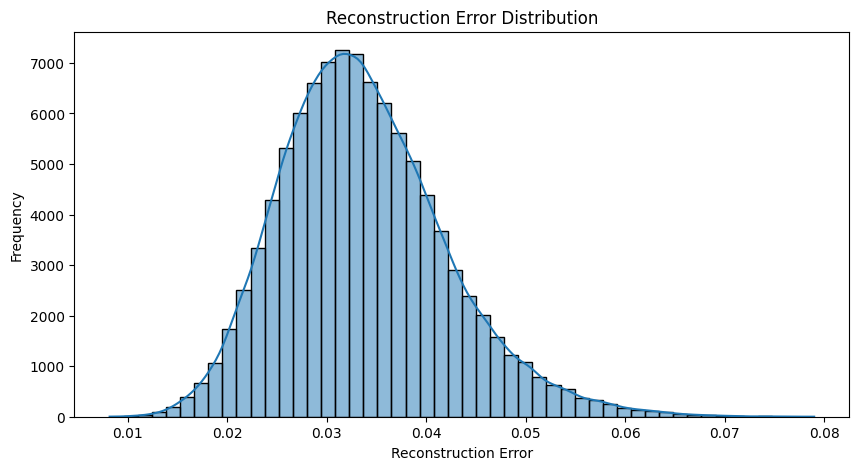

Number of anomalies detected: 4093
Anomalies:
       age  gender   latitude   longitude  country   city  \
74      35       2  80.599113  -43.046389      187  17973   
99      32       1  22.774843 -100.464612      106   1994   
125     56       0   9.034275  124.456874       47  23395   
165     51       0 -82.601785  176.468083       99  26871   
170     58       0 -53.282119 -141.551474      215  35381   
...    ...     ...        ...         ...      ...    ...   
99923   57       2  85.262886   91.764909        6   9970   
99941   40       2 -16.534191   87.291593       55  16781   
99963   32       2  38.810792  176.895148       29  25655   
99971   47       1 -76.723750  108.818574       40   5125   
99977   42       0  45.152191  -81.219406        6   2115   

       account_creation_date  account_type  subscription_plan  email_domain  \
74                       668             1                  2             3   
99                      1805             2                  1  

In [68]:
test_data = pd.read_csv('non_fraud_night_1.csv')


unnecessary_columns = ['user_id', 'account_number', 'transaction_id','Unnamed: 0']

test_data = test_data.drop(columns=[col for col in unnecessary_columns if col in test_data.columns])


categorical_features = test_data.select_dtypes(include=['object']).columns
for col in categorical_features:
    le = LabelEncoder()
    test_data[col] = le.fit_transform(test_data[col])

num_features = test_data.select_dtypes(include=[np.number]).columns

scaler = MinMaxScaler()

test_scaled = scaler.fit_transform(test_data[num_features])

autoencoder = keras.models.load_model("night_4.h5")


# Predict reconstruction error
reconstructed = autoencoder.predict(test_scaled)
mse = np.mean(np.power(test_scaled - reconstructed, 2), axis=1)

test_data["reconstruction_error"] = mse

# Plot reconstruction error distribution
plt.figure(figsize=(10, 5))
sns.histplot(test_data["reconstruction_error"], bins=50, kde=True)
plt.title("Reconstruction Error Distribution")
plt.xlabel("Reconstruction Error")
plt.ylabel("Frequency")
plt.show()


reconstruction_error = np.mean(np.square(test_scaled - reconstructed), axis=1)

threshold = 0.05#np.percentile(reconstruction_error, 96)  # Detect top 5% as anomalies

# Detect anomalies (values with reconstruction error greater than the threshold)
anomalies = test_data[reconstruction_error > threshold]

# Print the anomalies detected
print(f"Number of anomalies detected: {len(anomalies)}")
print("Anomalies:")
print(anomalies)